# 🧠 BleedCheck CT

### A second look at head CT scans: flagging possible brain bleeds, and testing what happens at a hospital the model has never seen

*Veritas AI International High School Hackathon 2026 · Health track*

**Authors:** Aarish Asif Khan and Aabir Asif Khan (Islamabad, Pakistan)

**Date:** 14 to 15 November 2026

**Code:** https://github.com/aarishasifkhan/veritas-hackathon-2026

> **This project is a prototype and is not medical advice.** It is a student research project built over one weekend on public data. It is not a medical device and has not been tested on patients.

---

## Why we built this
Both of us watched a stroke-related illness change our family. Strokes and brain bleeds are time-critical, and reading a head CT quickly and correctly matters.
We wanted to see how far a small, open model could get, and we wanted to be honest about where it breaks.

## Our question
Most demos report one big accuracy number on data from a single source. We asked something harder:

> **Does a bleed-detection model still work on scans from a different hospital, and how many scans from that hospital does it need to adapt?**

## Contents
1. Setup and data
2. Baselines: what does "good" have to beat?
3. The model and the tools to judge it
4. First model, and the problem we found
5. Can we fix it? Two ideas, tested honestly
6. A rule written before the final test, and the one-time final test
7. Where does it fail? Heatmaps
8. Our own question: how many local scans does a new hospital need?
9. Summary of results (filled in automatically)
10. Try it, limits, sources and tools

**How to run:** Kaggle notebook with a **GPU (T4)** and **Internet on**, with the two datasets below added as inputs. Click *Save & Run All*. It takes roughly 30 minutes.
**Every number in this notebook is produced by the cells below**, so the README, the video and the live demo can quote them directly.

## 1. Setup and data

In [1]:
import os, sys, platform, shutil, warnings, datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
warnings.filterwarnings("ignore")                      # keeps the output readable
pd.set_option("display.precision", 3); pd.set_option("display.width", 170)

# One small palette so every chart in the notebook looks like it belongs together
ACCENT, ACCENT_DARK, INK, MUTED, FLAG, GREY, BG = "#5B5BD6", "#3F3FB0", "#23264A", "#585D78", "#D6336C", "#8B8FA8", "#F3F4FB"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": BG, "axes.edgecolor": "#C9CEDC",
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
    "font.size": 11, "figure.dpi": 110, "axes.prop_cycle": plt.cycler(color=[ACCENT, GREY, FLAG, INK]),
})

# Note the environment, so anyone can reproduce this later
import torch, torchvision, sklearn
print("run date      :", datetime.date.today())
print("python        :", sys.version.split()[0], "|", platform.system())
print("torch         :", torch.__version__, "| torchvision:", torchvision.__version__, "| scikit-learn:", sklearn.__version__)
print("GPU           :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (this will be slow, turn on a GPU)")
print("input folders :", os.listdir("/kaggle/input"))

run date      : 2026-11-16
python        : 3.13.16 | Linux
torch         : 2.11.0+cu130 | torchvision: 0.26.0+cu130 | scikit-learn: 1.6.1
GPU           : Tesla T4
input folders : ['datasets']


### The data we use
We use two public sources, and we use them for different jobs.

| | **Main data** | **Second source ("a different hospital")** |
|---|---|---|
| **Name** | Brain Stroke CT Dataset (Kaggle, *ozguraslank*), a copy of the TEKNOFEST-2021 stroke data set | Head CT - hemorrhage (Kaggle, *Felipe Kitamura*) |
| **Who made it** | Republic of Türkiye Ministry of Health, labelled by radiologists | Felipe Kitamura |
| **Licence** | No standard open licence is named, only a rights statement, so we credit it in full and do not redistribute its images | CC0 (public domain) |
| **Size** | 6,650 slices: 4,427 Normal, 1,093 Bleeding, 1,130 Ischemia, plus 200 extra slices in `External_Test` | 200 slices: 100 normal, 100 hemorrhage |
| **Labels** | Class folders. `External_Test` has a yes/no stroke label only (130 no, 70 yes) | Normal or hemorrhage |
| **Patient IDs** | None (DICOM headers are anonymised) | None |
| **Our use** | Train, validation and test | **DEV** half: compare experiments and choose settings. **FINAL** half: look once, at the end |

**Two honest notes.** (1) The dataset page quotes 6,653 slices (4,428 / 1,094 / 1,131); the folders we downloaded contain 6,650, and we use what is in the folders.
(2) With no patient IDs, slices from the same patient may fall into different splits, so **same-source scores are an optimistic upper bound**. The second source is our real test.

**"Bleed" means the Bleeding class. "No bleed" means Normal or Ischemia.** We split the main data 70/15/15 (stratified by class) and the second source 50/50.

main data      : {'Normal': 4427, 'Ischemia': 1130, 'Bleeding': 1093} | share of bleeds: 0.164
train/val/test : 4655 997 998
External_Test  : 200 slices | Kitamura DEV/FINAL: 100 / 100


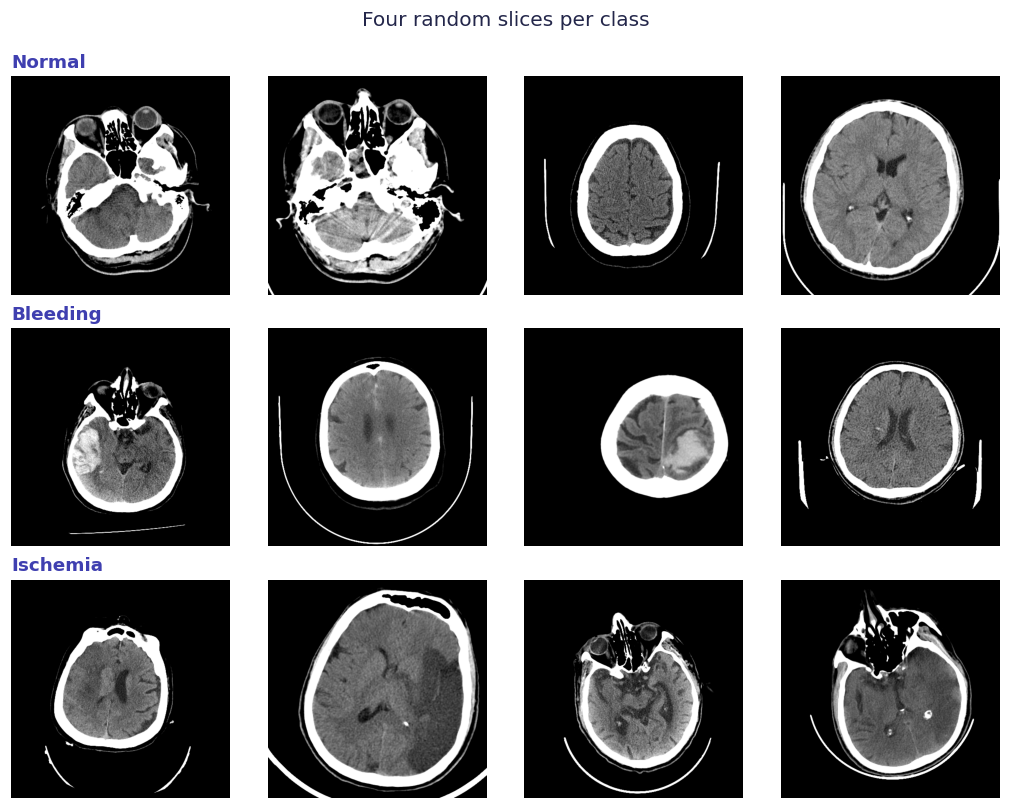

In [2]:
SEED = 42
CLASSES = ["Normal", "Bleeding", "Ischemia"]
base = "/kaggle/input/datasets/ozguraslank/brain-stroke-ct-dataset/Brain_Stroke_CT_Dataset"
kb = "/kaggle/input/datasets/felipekitamura/head-ct-hemorrhage"
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Put every image path into one table, so splitting and logging stay simple
rows = []
for cls in CLASSES:
    for f in sorted(os.listdir(f"{base}/{cls}/PNG")):
        rows.append({"id": f[:-4], "cls": cls, "png": f"{base}/{cls}/PNG/{f}"})
df = pd.DataFrame(rows)
df["bleed"] = (df["cls"] == "Bleeding").astype(int)

# 70% train, 15% validation, 15% test. Stratified, so every split keeps the same class mix
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["cls"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["cls"], random_state=SEED)

# The dataset authors also shipped a small held-out set. Its label is "any stroke" (yes/no)
ext = pd.read_csv(f"{base}/External_Test/labels.csv")
ext["png"] = [f"{base}/External_Test/PNG/{i}.png" for i in ext["image_id"]]
ext["stroke"] = ext["Stroke"].astype(int)

# The second source. DEV is for choosing things; FINAL stays untouched until the very end
kl = pd.read_csv(f"{kb}/labels.csv"); kl.columns = [c.strip() for c in kl.columns]
lab = kl.columns[1]
def kpath(i):
    s = str(i)
    return f"{kb}/head_ct/head_ct/{s}" if s.endswith(".png") else f"{kb}/head_ct/head_ct/{int(i):03d}.png"
kdf = pd.DataFrame({"png": [kpath(i) for i in kl.iloc[:, 0]], "bleed": kl[lab].astype(int).values})
kdev, kfin = train_test_split(kdf, test_size=0.5, stratify=kdf["bleed"], random_state=SEED)

# Quick sanity check before we trust anything else
print("main data      :", df["cls"].value_counts().to_dict(), "| share of bleeds:", round(df["bleed"].mean(), 3))
print("train/val/test :", len(train_df), len(val_df), len(test_df))
print("External_Test  :", len(ext), "slices | Kitamura DEV/FINAL:", len(kdev), "/", len(kfin))

# A look at the data itself: four random slices per class
fig, axes = plt.subplots(3, 4, figsize=(9.5, 7.4))
for r, cls in enumerate(CLASSES):
    for c, p in enumerate(df[df.cls == cls].sample(4, random_state=3)["png"]):
        axes[r, c].imshow(Image.open(p).convert("L"), cmap="gray"); axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left", color=ACCENT_DARK)
fig.suptitle("Four random slices per class", y=0.99); plt.tight_layout(); plt.show()

## 2. Baselines: what does "good" have to beat?
About 1 in 6 slices contains a bleed. A model that **always says "no bleed"** is right about 84% of the time and catches **zero** bleeds, so accuracy alone is misleading here.

We therefore report two things separately, as the hackathon brief asks:
- **Missed bleeds:** a real bleed the model did not flag (the dangerous mistake).
- **False alarms:** a non-bleed the model flagged (it wastes a doctor's time).

We also try a very simple learner (logistic regression on tiny 32×32 pixel images) so we can see how much the deep model actually adds.

In [3]:
from sklearn.linear_model import LogisticRegression

def report(name, y_true, y_pred, cls_true):
    # Prints accuracy, then the two mistakes we care about, separately
    y_true, y_pred, cls_true = np.asarray(y_true), np.asarray(y_pred), np.asarray(cls_true)
    tp = int(((y_true == 1) & (y_pred == 1)).sum()); fn = int(((y_true == 1) & (y_pred == 0)).sum())
    print(name)
    print(f"  accuracy     {np.mean(y_true == y_pred):.3f}")
    print(f"  bleed recall {tp / (tp + fn):.3f}   (missed bleeds: {fn} of {tp + fn})")
    for c in ["Normal", "Ischemia"]:
        m = cls_true == c
        print(f"  false alarms on {c}: {int((y_pred[m] == 1).sum())} of {int(m.sum())}")

def load_small(paths, size=32):
    # Shrink each scan to 32x32 grey pixels and flatten it into one row of numbers
    return np.stack([np.asarray(Image.open(p).convert("L").resize((size, size)), dtype=np.float32).ravel() / 255.0 for p in paths])

# Baseline 1: the lazy model that never raises an alarm
report("Baseline 1: always 'no bleed' (validation)", val_df["bleed"], np.zeros(len(val_df), dtype=int), val_df["cls"])

# Baseline 2: a plain linear model on raw pixels
Xtr, Xva = load_small(train_df["png"]), load_small(val_df["png"])
lr = LogisticRegression(max_iter=300, class_weight="balanced").fit(Xtr, train_df["bleed"])
report("Baseline 2: logistic regression on 32x32 pixels (validation)", val_df["bleed"], lr.predict(Xva), val_df["cls"])

Baseline 1: always 'no bleed' (validation)
  accuracy     0.836
  bleed recall 0.000   (missed bleeds: 164 of 164)
  false alarms on Normal: 0 of 664
  false alarms on Ischemia: 0 of 169
Baseline 2: logistic regression on 32x32 pixels (validation)
  accuracy     0.825
  bleed recall 0.744   (missed bleeds: 42 of 164)
  false alarms on Normal: 103 of 664
  false alarms on Ischemia: 29 of 169


**What to take from this.** The lazy model looks "84% accurate" and finds nothing. The pixel model finds some bleeds but raises many false alarms.
Any real model has to do much better on **both** mistakes.

## 3. The model and the tools to judge it
**The model.** A ResNet18 that was pretrained on ImageNet (transfer learning), fine-tuned to three classes: Normal, Bleeding, Ischemia. We use a **class-weighted loss** because bleeds are the minority, and we keep the epoch with the best validation bleed AUC.

**Why several seeds.** One training run can mislead. In our first attempt a single run flagged **59%** of the new source's normal scans as bleeds, and a re-run of the same recipe flagged **16%**. So every configuration is trained several times with different random seeds, and we report averages and ranges.

**Metrics.**
- *Recall (bleeds caught)* and *false-alarm rate* at the standard cut-off of 0.5.
- *AUC*: how well the model **ranks** bleed scans above non-bleed scans, regardless of the cut-off.

The cell below only defines tools. `evaluate_all` scores a model on validation, on the same-source `External_Test`, and on Kitamura **DEV**. It never touches the test split or Kitamura FINAL.

In [4]:
import torch.nn as nn, torch.nn.functional as F
import matplotlib.cm as cm
from PIL import ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False   # makes reruns match as closely as possible
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]                            # the ImageNet numbers the pretrained model expects

def autocontrast(im):
    return ImageOps.autocontrast(im, cutoff=1)    # stretch brightness so scans from different machines look more alike

def make_tf(train, aug=False, auto=False):
    # Builds the image pipeline. 'aug' adds random crops/rotations/brightness during training only
    steps = [T.Lambda(autocontrast)] if auto else []
    if train and aug:
        steps += [T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomRotation(10), T.ColorJitter(brightness=0.3, contrast=0.3)]
    else:
        steps += [T.Resize((224, 224))]
    return T.Compose(steps + [T.ToTensor(), T.Normalize(MEAN, STD)])

class DS(Dataset):
    # Minimal dataset: read one image, apply the pipeline, return it with its label
    def __init__(self, paths, labels, tf): self.p, self.y, self.tf = list(paths), list(labels), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

def probs(model, paths, tf_ev):
    # Returns the model's 3 class probabilities for every image in 'paths'
    dl = DataLoader(DS(paths, [0] * len(paths), tf_ev), batch_size=64, shuffle=False, num_workers=2)
    model.eval(); out = []
    with torch.no_grad():
        for xb, _ in dl: out.append(model(xb.to(device)).softmax(1).cpu().numpy())
    return np.concatenate(out)

def train_model(name, arch="resnet18", epochs=5, aug=False, auto=False, lr=3e-4):
    torch.manual_seed(SEED); np.random.seed(SEED)
    tf_tr, tf_ev = make_tf(True, aug, auto), make_tf(False, aug, auto)
    tr_dl = DataLoader(DS(train_df["png"], [CLASSES.index(c) for c in train_df["cls"]], tf_tr), batch_size=64, shuffle=True, num_workers=2)
    model = getattr(torchvision.models, arch)(weights="DEFAULT")     # start from ImageNet knowledge
    model.fc = nn.Linear(model.fc.in_features, 3)                    # new last layer: Normal / Bleeding / Ischemia
    model = model.to(device)
    counts = train_df["cls"].value_counts()
    w = torch.tensor([len(train_df) / (3 * counts[c]) for c in CLASSES], dtype=torch.float32).to(device)   # rarer class = bigger weight
    loss_fn = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_auc, best_state = 0, None
    for epoch in range(epochs):
        model.train()
        for xb, yb in tr_dl:
            opt.zero_grad(); loss_fn(model(xb.to(device)), yb.to(device)).backward(); opt.step()
        auc = roc_auc_score(val_df["bleed"], probs(model, val_df["png"].tolist(), tf_ev)[:, 1])
        print(f"  {name} epoch {epoch + 1}: validation bleed AUC {auc:.3f}")
        if auc > best_auc: best_auc, best_state = auc, {k: v.clone() for k, v in model.state_dict().items()}   # keep the best epoch
    model.load_state_dict(best_state)
    torch.save(best_state, f"/kaggle/working/{name}.pt")
    return model, tf_ev

def rec_fa(y, pred):
    # recall, false-alarm rate, missed bleeds, false alarms
    y, pred = np.asarray(y), np.asarray(pred)
    tp = int(((y == 1) & (pred == 1)).sum()); fn = int(((y == 1) & (pred == 0)).sum())
    fp = int(((y == 0) & (pred == 1)).sum()); neg = int((y == 0).sum())
    return tp / (tp + fn), fp / neg, fn, fp

LOG, STORE = [], {}      # LOG = one row of results per model; STORE = the raw probabilities
def evaluate_all(name, model, tf_ev, thr=0.5):
    P_val = probs(model, val_df["png"].tolist(), tf_ev)
    P_ext = probs(model, ext["png"].tolist(), tf_ev)
    P_kd = probs(model, kdev["png"].tolist(), tf_ev)
    STORE[name] = {"val": P_val, "ext": P_ext, "kdev": P_kd}
    r1, f1, _, _ = rec_fa(val_df["bleed"], P_val[:, 1] >= thr)
    r2, f2, _, _ = rec_fa(ext["stroke"], (1 - P_ext[:, 0]) >= thr)      # ExtTest only says "stroke yes/no", so use 1 - P(Normal)
    r3, f3, _, _ = rec_fa(kdev["bleed"], P_kd[:, 1] >= thr)
    LOG.append({"experiment": name,
        "val bleed recall": round(r1, 3), "val false-alarm rate": round(f1, 3),
        "val AUC": round(roc_auc_score(val_df["bleed"], P_val[:, 1]), 3),
        "ExtTest stroke recall": round(r2, 3), "ExtTest false-alarm rate": round(f2, 3),
        "KitDev bleed recall": round(r3, 3), "KitDev false-alarm rate": round(f3, 3),
        "KitDev AUC": round(roc_auc_score(kdev["bleed"], P_kd[:, 1]), 3)})
    pd.DataFrame(LOG).to_csv("/kaggle/working/experiment_log.csv", index=False)   # saved automatically, so nothing is lost

# The three recipes we compare, and how many times we train each
CONFIGS = {"E0_plain": {}, "E1_aug": {"aug": True}, "E2_aug_autocontrast": {"aug": True, "auto": True}}
SEEDS, EPOCHS = [42, 1, 2, 3], 5

def run(config, seed, epochs=EPOCHS):
    # Train one model with one seed, score it, and log it
    global SEED
    SEED = seed
    name = f"{config}_s{seed}"
    model, tf_ev = train_model(name, epochs=epochs, **CONFIGS[config])
    evaluate_all(name, model, tf_ev)
    SEED = 42
    return name

# ---- Grad-CAM: which parts of the image pushed the model towards "bleed"? ----
def load_model(name, arch="resnet18"):
    m = getattr(torchvision.models, arch)(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 3)
    m.load_state_dict(torch.load(f"/kaggle/working/{name}.pt", map_location=device))
    return m.to(device).eval()

def gradcam(model, x, class_idx=1):
    # Standard Grad-CAM: weight the last conv layer's maps by how much they raise the "bleed" score
    feats, grads = [], []
    def fwd(m, i, o):
        feats.append(o); o.register_hook(lambda g: grads.append(g))
    h = model.layer4.register_forward_hook(fwd)
    model.eval(); model.zero_grad()
    out = model(x); out[0, class_idx].backward(); h.remove()
    w = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats[0]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).detach().cpu().numpy()
    return cam, out.softmax(1)[0].detach().cpu().numpy()

def overlay(path, cam):
    g = np.asarray(Image.open(path).convert("L").resize((224, 224)), dtype=np.float32) / 255
    heat = cm.jet(cam)[..., :3]
    return (0.6 * np.stack([g] * 3, -1) + 0.4 * heat).clip(0, 1)     # scan in grey, heatmap on top

def gallery(model, tf_ev, items, title):
    if not items:
        print(title, "-> none"); return
    fig, axes = plt.subplots(1, len(items), figsize=(3.2 * len(items), 3.6)); axes = np.atleast_1d(axes)
    for ax, (path, text) in zip(axes, items):
        x = tf_ev(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
        cam, p = gradcam(model, x)
        ax.imshow(overlay(path, cam)); ax.axis("off"); ax.set_title(f"{text}\nP(bleed)={p[1]:.2f}", fontsize=9)
    fig.suptitle(title); plt.show()

def pick_threshold(y, p, min_recall=0.95):
    # Lowest false-alarm cut-off that still catches at least 95% of bleeds (chosen on DEV data only)
    best = None
    for t in np.unique(np.concatenate([[0.0], np.round(p, 4)])):
        r, f, _, _ = rec_fa(y, p >= t)
        if r >= min_recall and (best is None or f < best[1] or (f == best[1] and t > best[0])): best = (float(t), f, r)
    return best
print("tools ready")

tools ready


## 4. First model, and the problem we found
We train the plain model (`E0_plain`) with seed 42 and look at it on three kinds of data:
- **validation:** same source as training,
- **`External_Test`:** the dataset authors' own held-out slices (same source, "any stroke" label),
- **Kitamura DEV:** a **different source**.

In [5]:
first = run("E0_plain", 42)                      # trains for 5 epochs, prints the validation AUC after each

cols = ["val bleed recall", "val false-alarm rate", "val AUC",
        "ExtTest stroke recall", "ExtTest false-alarm rate",
        "KitDev bleed recall", "KitDev false-alarm rate", "KitDev AUC"]
pd.DataFrame(LOG).set_index("experiment")[cols].T

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 199MB/s]


  E0_plain_s42 epoch 1: validation bleed AUC 0.984
  E0_plain_s42 epoch 2: validation bleed AUC 0.993
  E0_plain_s42 epoch 3: validation bleed AUC 0.967
  E0_plain_s42 epoch 4: validation bleed AUC 0.991
  E0_plain_s42 epoch 5: validation bleed AUC 0.988


experiment,E0_plain_s42
val bleed recall,0.872
val false-alarm rate,0.004
val AUC,0.993
ExtTest stroke recall,0.786
ExtTest false-alarm rate,0.031
KitDev bleed recall,0.920
KitDev false-alarm rate,0.200
KitDev AUC,0.955


**What to look for.** On data like its training data the model ranks scans very well (validation AUC close to 0.99).
On the second source, bleed recall usually stays high **but many normal scans get flagged**, and the AUC drops.
That is *dataset shift*: a different scanner, protocol or hospital changes how scans look, and the model's cut-off no longer fits.
A single accuracy number on one source would never have shown this.

## 5. Can we fix it? Two ideas, tested honestly
- **E1: augmentation.** During training the model sees randomly cropped, slightly rotated and brightness-shifted scans, so it should depend less on exactly how a scan looks.
- **E2: augmentation plus contrast stretching.** We also stretch every scan's contrast before the model sees it, to make scans from different machines look more alike.

Because one run can mislead, **each recipe is trained with four seeds** (42, 1, 2, 3) and we compare averages and ranges. This is the slowest part of the notebook.

In [6]:
# Train every recipe with every seed (skipping the one we already trained above)
for cfg in CONFIGS:
    for s in SEEDS:
        if f"{cfg}_s{s}" not in STORE:
            print(f"training {cfg}, seed {s}")
            run(cfg, s)

L = pd.DataFrame(LOG)
L["config"] = L["experiment"].str.extract(r"^(.*)_s\d+$")[0]      # which recipe a row belongs to
L.set_index("experiment")[cols]

training E0_plain, seed 1
  E0_plain_s1 epoch 1: validation bleed AUC 0.983
  E0_plain_s1 epoch 2: validation bleed AUC 0.988
  E0_plain_s1 epoch 3: validation bleed AUC 0.991
  E0_plain_s1 epoch 4: validation bleed AUC 0.993
  E0_plain_s1 epoch 5: validation bleed AUC 0.995
training E0_plain, seed 2
  E0_plain_s2 epoch 1: validation bleed AUC 0.953
  E0_plain_s2 epoch 2: validation bleed AUC 0.985
  E0_plain_s2 epoch 3: validation bleed AUC 0.994
  E0_plain_s2 epoch 4: validation bleed AUC 0.995
  E0_plain_s2 epoch 5: validation bleed AUC 0.994
training E0_plain, seed 3
  E0_plain_s3 epoch 1: validation bleed AUC 0.979
  E0_plain_s3 epoch 2: validation bleed AUC 0.967
  E0_plain_s3 epoch 3: validation bleed AUC 0.994
  E0_plain_s3 epoch 4: validation bleed AUC 0.997
  E0_plain_s3 epoch 5: validation bleed AUC 0.998
training E1_aug, seed 42
  E1_aug_s42 epoch 1: validation bleed AUC 0.983
  E1_aug_s42 epoch 2: validation bleed AUC 0.976
  E1_aug_s42 epoch 3: validation bleed AUC 0.982


,val bleed recall,val false-alarm rate,val AUC,ExtTest stroke recall,ExtTest false-alarm rate,KitDev bleed recall,KitDev false-alarm rate,KitDev AUC
experiment,,,,,,,,
E0_plain_s42,0.872,0.004,0.993,0.786,0.031,0.92,0.20,0.955
E0_plain_s1,0.939,0.019,0.995,0.886,0.062,1.00,0.44,0.960
E0_plain_s2,0.915,0.000,0.995,0.914,0.069,0.94,0.36,0.888
E0_plain_s3,0.970,0.013,0.998,0.843,0.054,0.94,0.22,0.960
E1_aug_s42,0.884,0.000,0.991,0.914,0.192,0.82,0.00,0.960
E1_aug_s1,0.841,0.001,0.990,0.943,0.154,1.00,0.24,0.964
E1_aug_s2,0.909,0.005,0.996,0.971,0.246,0.98,0.12,0.995
E1_aug_s3,0.872,0.002,0.992,0.843,0.077,0.94,0.10,0.973
E2_aug_autocontrast_s42,0.884,0.000,0.991,0.914,0.192,0.84,0.00,0.964


config,E0_plain,E1_aug,E2_aug_autocontrast
val bleed recall,0.924 (0.872-0.970),0.877 (0.841-0.909),0.877 (0.841-0.909)
val false-alarm rate,0.009 (0.000-0.019),0.002 (0.000-0.005),0.002 (0.000-0.005)
val AUC,0.995 (0.993-0.998),0.992 (0.990-0.996),0.992 (0.990-0.996)
ExtTest stroke recall,0.857 (0.786-0.914),0.918 (0.843-0.971),0.918 (0.843-0.971)
ExtTest false-alarm rate,0.054 (0.031-0.069),0.167 (0.077-0.246),0.167 (0.077-0.246)
KitDev bleed recall,0.950 (0.920-1.000),0.935 (0.820-1.000),0.935 (0.840-1.000)
KitDev false-alarm rate,0.305 (0.200-0.440),0.115 (0.000-0.240),0.105 (0.000-0.220)
KitDev AUC,0.941 (0.888-0.960),0.973 (0.960-0.995),0.975 (0.964-0.995)


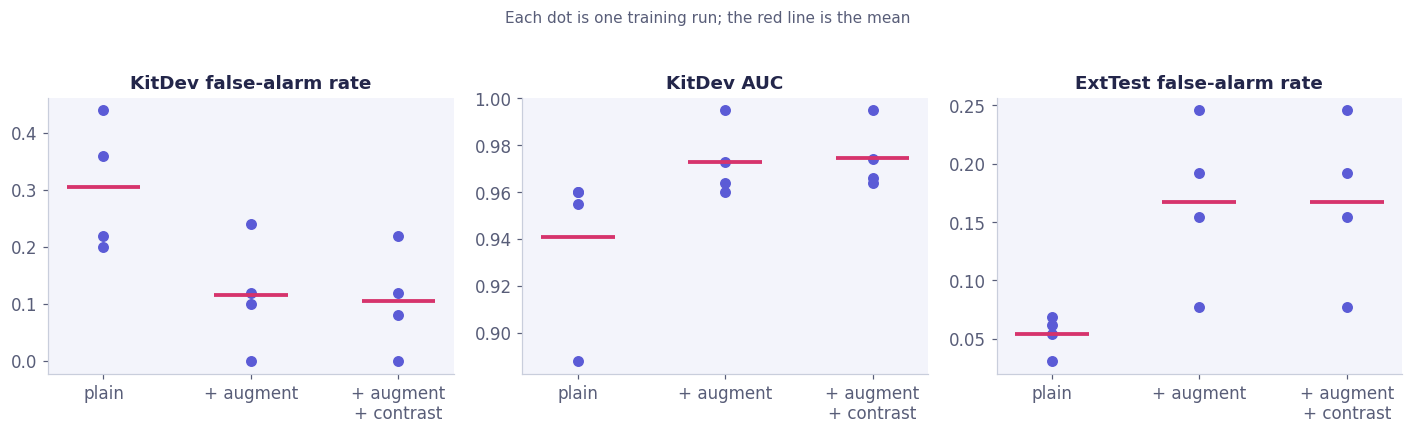

In [7]:
# Average and range over the four seeds of each recipe
fmt = lambda s: f"{s.mean():.3f} ({s.min():.3f}-{s.max():.3f})"
display(L.groupby("config")[cols].agg(fmt).T)

# Same story as a picture: each dot is one training run
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, ["KitDev false-alarm rate", "KitDev AUC", "ExtTest false-alarm rate"]):
    for i, cfg in enumerate(CONFIGS):
        v = L[L.config == cfg][col].values
        ax.scatter([i] * len(v), v, color=ACCENT, s=38, zorder=3)
        ax.hlines(v.mean(), i - 0.25, i + 0.25, color=FLAG, lw=2.5, zorder=4)
    ax.set_xticks(range(3)); ax.set_xticklabels(["plain", "+ augment", "+ augment\n+ contrast"]); ax.set_title(col)
fig.suptitle("Each dot is one training run; the red line is the mean", y=1.03, color=MUTED, fontsize=10)
plt.tight_layout(); plt.show()

**Reading the chart.** In our experience, augmentation and contrast stretching mostly **move** the trade-off (more bleeds caught, more false alarms) rather than improve the ranking quality (AUC), and the spread between seeds of the *same* recipe is about as large as the gap between recipes.
So we only claim an improvement if the averages clearly beat that spread. If they do not, that is a real finding too, and we say so.

## 6. A rule written before the final test, and the one-time final test
To avoid picking a model because it *happened* to score well on data we had already looked at, we fixed a rule **before** touching the test split or Kitamura FINAL:

> Among the recipes whose **average validation bleed recall** is not more than 2 points below the plain model's, **and** whose **average same-source false-alarm rate** (`External_Test`) is not more than 5 points above the plain model's, choose the one with the **best average KitDev AUC**.

*How the rule changed (for honesty).* Our first version only looked at KitDev AUC and ignored that augmentation raised same-source false alarms a lot. We added the second condition **before** running the multi-seed experiments.
The rule only uses validation, `External_Test` and Kitamura DEV.

In [8]:
g = L.groupby("config")[cols].mean()
E0 = g.loc["E0_plain"]

# Which recipes pass the two conditions?
ok = [c for c in g.index
      if g.loc[c, "val bleed recall"] >= E0["val bleed recall"] - 0.02
      and g.loc[c, "ExtTest false-alarm rate"] <= E0["ExtTest false-alarm rate"] + 0.05]
chosen = max(ok, key=lambda c: g.loc[c, "KitDev AUC"])           # best KitDev AUC among those that pass
print("recipes that pass the rule:", ok)
print("CHOSEN recipe             :", chosen)

# For the demo we need one concrete model: the seed with the best VALIDATION AUC
names = [n for n in L["experiment"] if n.startswith(chosen + "_s")]
cand = L[L["experiment"].isin(names)].sort_values("val AUC", ascending=False)
demo_name = cand.iloc[0]["experiment"]
print("models of that recipe     :", names)
print("demo model                :", demo_name, "(highest validation AUC)")

cfg = CONFIGS[chosen]; tf_f = make_tf(False, cfg.get("aug", False), cfg.get("auto", False))   # the image pipeline that recipe uses
g[["val bleed recall", "ExtTest false-alarm rate", "KitDev AUC"]]

recipes that pass the rule: ['E0_plain']
CHOSEN recipe             : E0_plain
models of that recipe     : ['E0_plain_s42', 'E0_plain_s1', 'E0_plain_s2', 'E0_plain_s3']
demo model                : E0_plain_s3 (highest validation AUC)


,val bleed recall,ExtTest false-alarm rate,KitDev AUC
config,,,
E0_plain,0.924,0.054,0.941
E1_aug,0.877,0.167,0.973
E2_aug_autocontrast,0.877,0.167,0.975


### The final test (looked at once)
Now, **for the first time**, the chosen recipe's models see the test split (same source) and Kitamura FINAL (new source). We do this once and do not go back and change the choice afterwards.
We also try *recalibration*: keeping the model but moving the cut-off so that it catches at least 95% of bleeds on Kitamura DEV, then checking that cut-off on Kitamura FINAL.

In [9]:
yt, yk = test_df["bleed"].values, kfin["bleed"].values
rows_ = []
for nm in names:
    m = load_model(nm)
    Pt = probs(m, test_df["png"].tolist(), tf_f)[:, 1]                 # same-source test split
    Pk = probs(m, kfin["png"].tolist(), tf_f)[:, 1]                    # new-source FINAL half
    tk = pick_threshold(kdev["bleed"].values, STORE[nm]["kdev"][:, 1])[0]   # cut-off chosen on DEV only
    r_t, f_t, _, _ = rec_fa(yt, Pt >= 0.5)
    r_k, f_k, _, _ = rec_fa(yk, Pk >= 0.5)
    r_c, f_c, _, _ = rec_fa(yk, Pk >= tk)
    rows_.append({"model": nm,
        "test bleeds caught": r_t, "test false alarms": f_t, "test AUC": roc_auc_score(yt, Pt),
        "new-source bleeds caught": r_k, "new-source false alarms": f_k, "new-source AUC": roc_auc_score(yk, Pk),
        "new-source recalibrated caught": r_c, "new-source recalibrated false alarms": f_c})
res = pd.DataFrame(rows_).set_index("model")
display(res.T)
print("\nmean (min-max) over the models of the chosen recipe:")
print(res.apply(fmt).to_string())

model,E0_plain_s42,E0_plain_s1,E0_plain_s2,E0_plain_s3
test bleeds caught,0.829,0.963,0.915,0.976
test false alarms,0.006,0.025,0.010,0.028
test AUC,0.991,0.997,0.996,0.998
new-source bleeds caught,0.980,1.000,0.960,1.000
new-source false alarms,0.200,0.480,0.260,0.160
new-source AUC,0.950,0.954,0.893,0.985
new-source recalibrated caught,1.000,0.960,1.000,1.000
new-source recalibrated false alarms,0.440,0.140,0.360,0.180



mean (min-max) over the models of the chosen recipe:
test bleeds caught                      0.921 (0.829-0.976)
test false alarms                       0.017 (0.006-0.028)
test AUC                                0.996 (0.991-0.998)
new-source bleeds caught                0.985 (0.960-1.000)
new-source false alarms                 0.275 (0.160-0.480)
new-source AUC                          0.946 (0.893-0.985)
new-source recalibrated caught          0.990 (0.960-1.000)
new-source recalibrated false alarms    0.280 (0.140-0.440)


**How to read the table.**
- **test** columns: data like the training data. This is an *optimistic upper bound*, because we have no patient IDs.
- **new-source** columns: the Kitamura half nobody had looked at. This is the more honest number.
- **recalibrated**: only the cut-off was moved. If that helps at all, it is not reliable from one seed to the next.

## 7. Where does it fail? Heatmaps (Grad-CAM)
A Grad-CAM heatmap highlights the image regions that pushed the model towards "bleed": red and yellow mean "pushed hard".
We look at the demo model on validation and on the new source (DEV only, so the final test stays untouched).

**Important:** a heatmap shows what *drove the score*. It does **not** prove the model found the bleed.

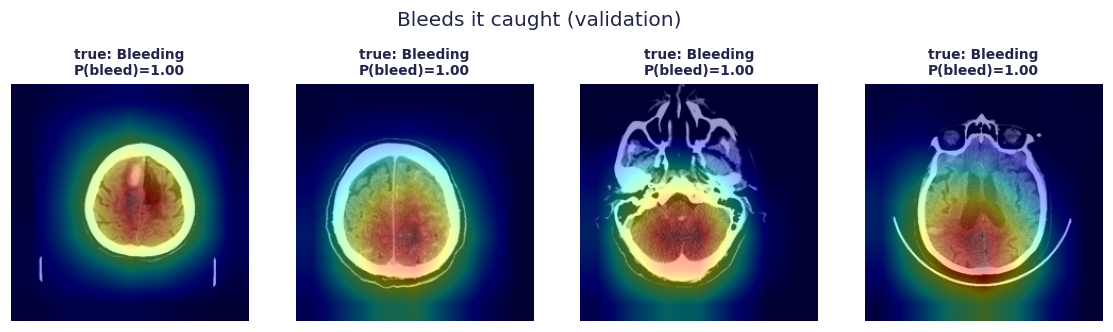

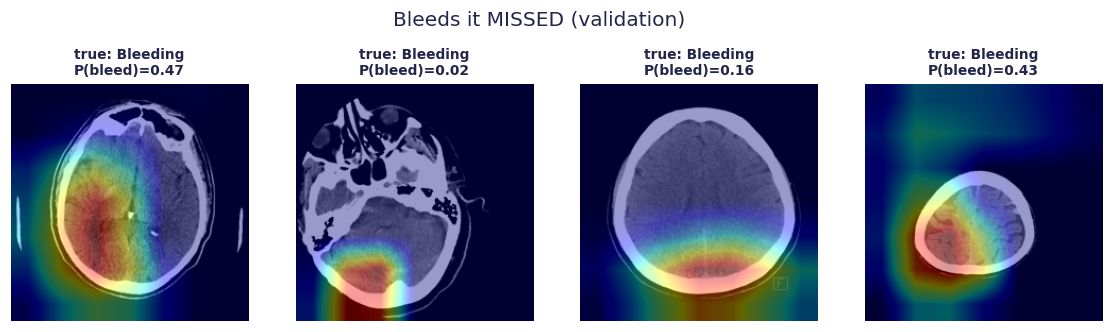

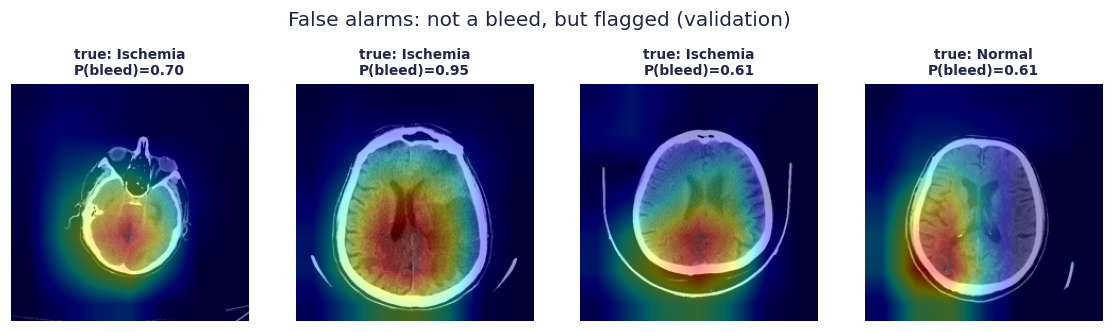

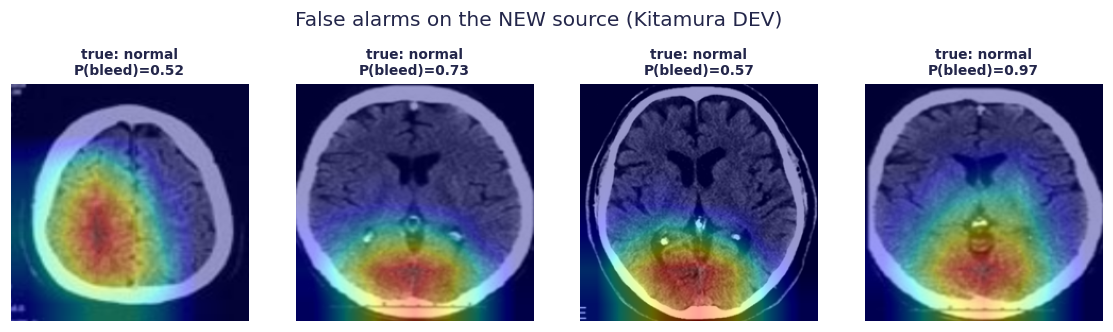

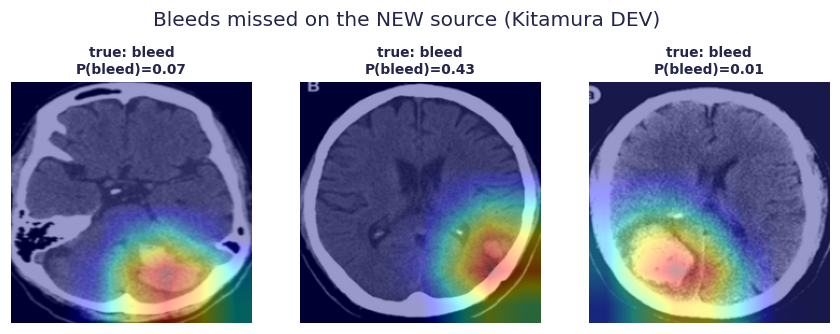

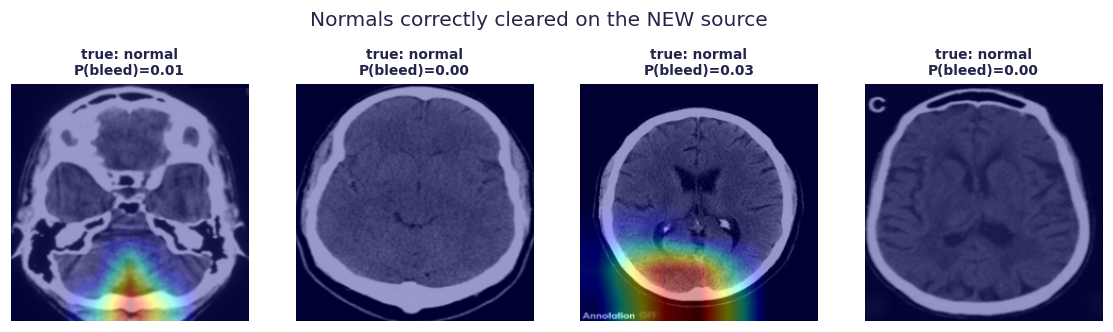

In [10]:
model = load_model(demo_name)

v = val_df.reset_index(drop=True); pv = STORE[demo_name]["val"][:, 1] >= 0.5
def pick(d, mask, n, label):
    return [(d.loc[i, "png"], label(d.loc[i])) for i in np.where(mask)[0][:n]]      # first n images that match the condition
vl = lambda r: f"true: {r['cls']}"

# Same source: what it gets right, what it misses, what it wrongly flags
gallery(model, tf_f, pick(v, (v.bleed.values == 1) & pv, 4, vl), "Bleeds it caught (validation)")
gallery(model, tf_f, pick(v, (v.bleed.values == 1) & ~pv, 4, vl), "Bleeds it MISSED (validation)")
gallery(model, tf_f, pick(v, (v.bleed.values == 0) & pv, 4, vl), "False alarms: not a bleed, but flagged (validation)")

# New source: the same three questions
k = kdev.reset_index(drop=True); pk = STORE[demo_name]["kdev"][:, 1] >= 0.5
kl_ = lambda r: "true: bleed" if r["bleed"] == 1 else "true: normal"
gallery(model, tf_f, pick(k, (k.bleed.values == 0) & pk, 4, kl_), "False alarms on the NEW source (Kitamura DEV)")
gallery(model, tf_f, pick(k, (k.bleed.values == 1) & ~pk, 4, kl_), "Bleeds missed on the NEW source (Kitamura DEV)")
gallery(model, tf_f, pick(k, (k.bleed.values == 0) & ~pk, 4, kl_), "Normals correctly cleared on the NEW source")

**What we see.** In the "MISSED" and "false alarm" rows, the highlighted area often sits on the **skull edge, the back of the head, the head-holder, or image corners and text overlays**, rather than clearly on brain tissue.
So the model may lean on cues that are *not* the bleed itself. We list this as a limitation. We are not radiologists, and we do **not** claim the heatmaps locate bleeds.

## 8. Our own question: how many scans from the new hospital does the model need?
We take the demo model and **fine-tune it briefly** (5 epochs, small learning rate) on a few labelled scans from the new source (Kitamura DEV): 0, 10, 20, 40 or 100 scans, half bleeds and half normal.
Then we test on Kitamura FINAL (never used for training), and we also check that the model did not **forget** the original source (validation split).
Each size is repeated with 3 random draws of the local scans, so we can see how much the result depends on which scans were picked.

local scans used,0,10,20,40,100
Kit recall,1.000 (1.000-1.000),0.907 (0.860-0.940),0.953 (0.880-1.000),0.953 (0.940-0.980),0.960 (0.960-0.960)
Kit false-alarm,0.160 (0.160-0.160),0.040 (0.040-0.040),0.060 (0.060-0.060),0.013 (0.000-0.040),0.020 (0.020-0.020)
Kit AUC,0.985 (0.985-0.985),0.989 (0.984-0.994),0.988 (0.976-0.997),0.998 (0.997-0.999),0.999 (0.999-0.999)
main-source recall,0.970 (0.970-0.970),0.888 (0.854-0.915),0.890 (0.860-0.945),0.864 (0.811-0.909),0.909 (0.860-0.939)
main-source false-alarm,0.013 (0.013-0.013),0.000 (0.000-0.000),0.000 (0.000-0.000),0.002 (0.000-0.005),0.047 (0.031-0.067)


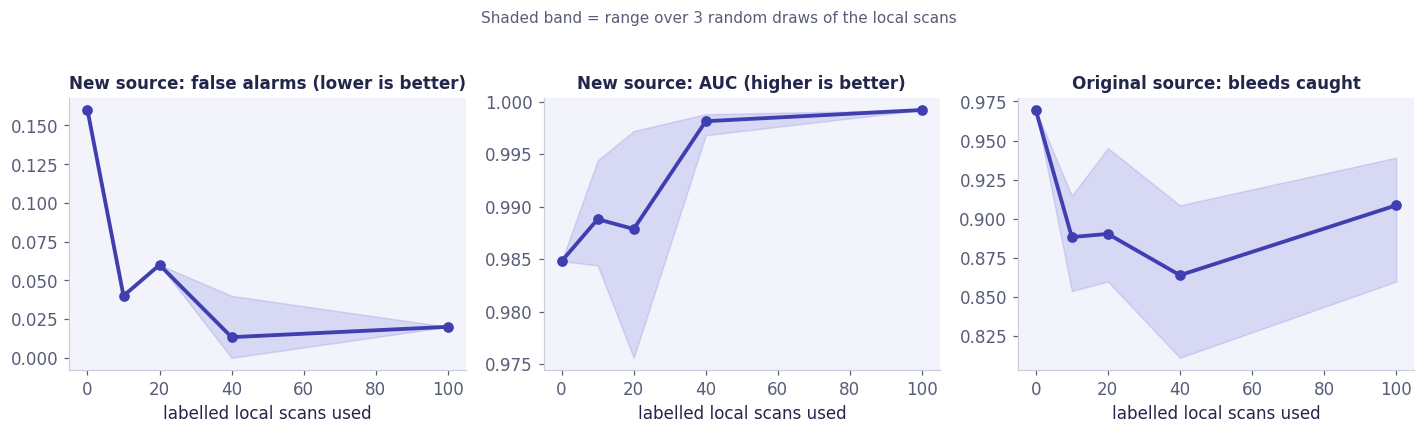

In [11]:
def adapt_and_test(base_name, n, seed, epochs=5, lr=1e-4):
    # Fine-tune a copy of the model on n labelled "local" scans, then test it
    torch.manual_seed(seed)
    model = load_model(base_name)
    if n > 0:
        sub = pd.concat([kdev[kdev["bleed"] == c].sample(n // 2, random_state=seed) for c in (0, 1)])   # half bleeds, half normal
        dl = DataLoader(DS(sub["png"], sub["bleed"].tolist(), tf_f), batch_size=16, shuffle=True, num_workers=2)
        opt = torch.optim.Adam(model.parameters(), lr=lr); loss_fn = nn.CrossEntropyLoss()
        for _ in range(epochs):
            model.train()
            for xb, yb in dl:
                opt.zero_grad(); loss_fn(model(xb.to(device)), yb.to(device)).backward(); opt.step()
    Pk = probs(model, kfin["png"].tolist(), tf_f)[:, 1]                 # new source (never trained on)
    Pv = probs(model, val_df["png"].tolist(), tf_f)[:, 1]               # original source: did it forget?
    r, f, _, _ = rec_fa(kfin["bleed"], Pk >= 0.5)
    rv, fv, _, _ = rec_fa(val_df["bleed"], Pv >= 0.5)
    return {"local scans used": n, "Kit recall": r, "Kit false-alarm": f, "Kit AUC": roc_auc_score(kfin["bleed"], Pk),
            "main-source recall": rv, "main-source false-alarm": fv}

out = []
for n in [0, 10, 20, 40, 100]:
    for s in ([0] if n == 0 else [1, 2, 3]):          # n=0 needs no random draw
        out.append(adapt_and_test(demo_name, n, s))
adapt = pd.DataFrame(out)
display(adapt.groupby("local scans used").agg(fmt).T)

# The same table as three small charts (shaded band = range over the 3 draws)
A = adapt.groupby("local scans used").agg(["mean", "min", "max"])
x = A.index.values
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, title in zip(axes, ["Kit false-alarm", "Kit AUC", "main-source recall"],
                          ["New source: false alarms (lower is better)", "New source: AUC (higher is better)", "Original source: bleeds caught"]):
    ax.fill_between(x, A[(col, "min")], A[(col, "max")], color=ACCENT, alpha=0.18)
    ax.plot(x, A[(col, "mean")], color=ACCENT_DARK, lw=2.5, marker="o")
    ax.set_xlabel("labelled local scans used"); ax.set_title(title, fontsize=11)
fig.suptitle("Shaded band = range over 3 random draws of the local scans", y=1.03, color=MUTED, fontsize=10)
plt.tight_layout(); plt.show()

**Reading the charts.** If the two left charts improve as local scans are added, a hospital could adapt the tool with a modest number of its own labelled scans.
The right chart shows the **cost**: whether the model got worse on the original kind of scan. This is one new source and 100 test scans, so we treat the result as a **lead, not a guarantee**.

## 9. Summary of results (filled in automatically from the cells above)
These lines are generated by code, so they always match the tables. The README, the video and the demo page quote **these** numbers.

In [12]:
def pct(s):
    return f"{s.mean():.1%} (range {s.min():.1%} to {s.max():.1%})"

a = adapt.groupby("local scans used").mean()
print(f"Chosen recipe: {chosen}  ({len(names)} training runs with different seeds)\n")
print(f"Data like the training data (test split):")
print(f"   bleeds caught {pct(res['test bleeds caught'])}")
print(f"   false alarms  {pct(res['test false alarms'])} | AUC {res['test AUC'].mean():.3f}\n")
print(f"A new source (Kitamura FINAL, cut-off 0.5):")
print(f"   bleeds caught {pct(res['new-source bleeds caught'])}")
print(f"   false alarms  {pct(res['new-source false alarms'])} | AUC {res['new-source AUC'].mean():.3f}\n")
print(f"Moving only the cut-off (recalibration) on the new source:")
print(f"   bleeds caught {pct(res['new-source recalibrated caught'])}")
print(f"   false alarms  {pct(res['new-source recalibrated false alarms'])}\n")
print(f"Fine-tuning on local scans (demo model {demo_name}):")
print(f"   0 local scans  : false alarms {a.loc[0, 'Kit false-alarm']:.1%}, AUC {a.loc[0, 'Kit AUC']:.3f}, bleeds caught {a.loc[0, 'Kit recall']:.1%}")
print(f"   100 local scans: false alarms {a.loc[100, 'Kit false-alarm']:.1%}, AUC {a.loc[100, 'Kit AUC']:.3f}, bleeds caught {a.loc[100, 'Kit recall']:.1%}")
print(f"   original source bleeds caught: {a.loc[0, 'main-source recall']:.1%} before, {a.loc[100, 'main-source recall']:.1%} after 100 local scans")

Chosen recipe: E0_plain  (4 training runs with different seeds)

Data like the training data (test split):
   bleeds caught 92.1% (range 82.9% to 97.6%)
   false alarms  1.7% (range 0.6% to 2.8%) | AUC 0.996

A new source (Kitamura FINAL, cut-off 0.5):
   bleeds caught 98.5% (range 96.0% to 100.0%)
   false alarms  27.5% (range 16.0% to 48.0%) | AUC 0.946

Moving only the cut-off (recalibration) on the new source:
   bleeds caught 99.0% (range 96.0% to 100.0%)
   false alarms  28.0% (range 14.0% to 44.0%)

Fine-tuning on local scans (demo model E0_plain_s3):
   0 local scans  : false alarms 16.0%, AUC 0.985, bleeds caught 100.0%
   100 local scans: false alarms 2.0%, AUC 0.999, bleeds caught 96.0%
   original source bleeds caught: 97.0% before, 90.9% after 100 local scans


## 10. Try it, limits, sources and tools

### Try it
The interactive demo is a separate web app hosted on Streamlit: **https://bleedcheck-ct.streamlit.app/**.

It uses the demo model chosen above. The next cell saves that model's weights and a few public example scans for the app.

In [13]:
# Save the demo model's weights and a few public example scans (Kitamura is CC0, so it is fine to share them)
shutil.copy(f"/kaggle/working/{demo_name}.pt", "/kaggle/working/bleedcheck_weights.pt")
os.makedirs("/kaggle/working/examples", exist_ok=True)
for i, (_, r) in enumerate(pd.concat([kdev[kdev.bleed == 1].head(3), kdev[kdev.bleed == 0].head(3)]).iterrows()):
    shutil.copy(r["png"], f"/kaggle/working/examples/kitamura_{'bleed' if r.bleed == 1 else 'normal'}_{i}{os.path.splitext(r['png'])[1]}")
print("saved bleedcheck_weights.pt from", demo_name, "and", len(os.listdir("/kaggle/working/examples")), "example scans")

saved bleedcheck_weights.pt from E0_plain_s3 and 6 example scans


### Limits and honesty notes
- **Research prototype, not medical advice.** It is not a medical device and has not been validated clinically. A flag means "look closer". A clear result does **not** rule out a bleed.
- **No patient IDs.** Slices of the same patient may sit on both sides of a split, so same-source scores are optimistic.
- **One extra source, 100 scans.** The new-source numbers come from a single small public set. Differences of a few scans are noise.
- **Label caveat.** `External_Test` only has a stroke yes/no label, so we use "1 minus P(Normal)" there.
- **Heatmaps are not proof.** The model may use skull, background or marker cues.
- **Mistakes we made and fixed.** An early test run used a placeholder model before the model was chosen; we documented it and kept the rule's choice. Our first decision rule also missed one condition, which we corrected before the multi-seed runs. See `docs/experiment_log.md`.
- **No real patient records** were used anywhere in this project, and the demo asks people not to upload any.

### What we would do next
Patient-level splits where IDs exist, more hospitals and scanners, masking the skull and background, and testing with clinicians.

### Sources and credits
- **Main data:** Brain Stroke CT Dataset on Kaggle (ozguraslank), a copy of the TEKNOFEST-2021 Stroke data set. Koç U, Akçapınar Sezer E, Alper Özkaya Y, et al. *Eurasian J Med.* 2022;54(3):248-258.
- **Second source:** Kitamura, F. *Head CT - hemorrhage*, Kaggle (CC0). https://doi.org/10.34740/KAGGLE/DSV/152137
- **Methods:** ResNet18 (He et al., 2016) with ImageNet weights via torchvision; Grad-CAM (Selvaraju et al., 2017); PyTorch, cikit-learn, pandas, matplotlib; demo built with Streamlit (first prototyped in Gradio).

### AI tools we used
We used Claude (Anthropic) as our main AI assistant. It helped us plan the project, explained concepts, and wrote and debugged much of the code, which we ran, checked and adjusted ourselves. We used ChatGPT only to brainstorm project names. Its suggestions promised more than our project delivers, so we asked Claude for alternatives and chose BleedCheck CT ourselves. We ran every experiment and decided what to keep or drop. Some of this write-up was drafted with Claude and edited by us. No other AI tools were used. We can explain every step.

> **This project is a prototype and is not medical advice.**